1. Configuração e bibliotecas

In [1]:
from pathlib import Path
from datetime import datetime, timedelta, timezone
from getpass import getpass
import time
import os

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)

BASE_URL = "http://andromeda.lasdpc.icmc.usp.br:60106"
PROJECT_ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "code/sensores.json").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Execute dentro de temperatureMonitoring.")
ROOT = PROJECT_ROOT / "code/tcc"
RAW_DIR = ROOT / "data" / "raw" / "smartlab"
META_DIR = ROOT / "data" / "metadata"
FIG_DIR = ROOT / "results" / "figuras"
for pasta in (RAW_DIR, META_DIR, FIG_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

# Primeiro teste: 1 dia. Após validar, altere EXECUTAR_PERIODO_COMPLETO para True.
INICIO = "2026-06-28T00:00:00Z"
FIM = "2026-06-29T00:00:00Z"

EXECUTAR_PERIODO_COMPLETO = True
INICIO_COMPLETO = "2026-06-10T00:00:00Z"
FIM_COMPLETO = "2026-07-26T00:00:00Z"
TIME_BUCKET = "5min"  # opções: 5min, 15min, 30min, 1 hour, 2 hours
TIPO_TEMPERATURA = 1  # valor testado; confirmar no catálogo de tipos abaixo

if EXECUTAR_PERIODO_COMPLETO:
    INICIO, FIM = INICIO_COMPLETO, FIM_COMPLETO
print("Janela selecionada:", INICIO, "até", FIM)


Janela selecionada: 2026-06-10T00:00:00Z até 2026-07-26T00:00:00Z


2. Inventário espacial dos sensores
As coordenadas não são levantamentos de precisão: as dimensões da sala foram medidas e as posições dos dispositivos foram estimadas visualmente. Distâncias calculadas posteriormente serão apenas exploratórias.

Os IDs e os ambientes abaixo vêm do cadastro consultado anteriormente. Confirme os IDs do laboratório principal e da sala de reunião na resposta atual de /device antes de interpretar os resultados.

In [2]:
sensores = [
    (887,   "1006-esp32-temphum-09",        "1006",    1, 0,   0),
    (86790, "1006-esp32-temphum-02",        "1006",    1, 3,   1.4),
    (86791, "1006-esp32-temphum-03",        "1006",    1, 5,   1.4),
    (86793, "1006-esp32-temphum-08",        "1006",    1, 8,   0),
    (891,   "1006-esp32-temphum-06",        "1006",    1, 0,   4.9),
    (1025,  "1008Reuniao-esp32-temphum-03", "Reuniao", 2, 3,   4.2),
    (86801, "1008Reuniao-esp32-temphum-04", "Reuniao", 2, 5,   4.2),
    (48, '1006-esp32-temphum-07', '1006', 1, 8, 5.6),
    (86796, "1006Cluster-esp32-temphum-03", "Cluster", 3, 0,   7),
    (885,   "1006Cluster-esp32-temphum-04", "Cluster", 3, 0,   5.6),
    (86797, "1006Cluster-esp32-temphum-05", "Cluster", 3, 3,   6.3),
    (86786, "1006Cluster-esp32temphum-06",  "Cluster", 3, 4.5, 6.3),
    (86795, "1006Cluster-esp32temphum-02",  "Cluster", 3, 6,   7),
    (86794, "1006Cluster-esp32temphum-01",  "Cluster", 3, 6,   5.6),
]
# Ler o cadastro confirmado como literal, sem executar código do arquivo.
import ast
arvore = ast.parse((PROJECT_ROOT / "code/sensorsWithCoordinates").read_text())
posicoes = ast.literal_eval(arvore.body[0].value)
sensores = [(*r[:4], *posicoes[r[1]]) for r in sensores]
colunas = ["id_device", "nome", "regiao", "id_environment", "x_aprox", "y_aprox"]
metadata = pd.DataFrame(sensores, columns=colunas)
assert len(metadata) == 14 and metadata.id_device.is_unique
metadata.to_csv(META_DIR / "sensores.csv", index=False)
display(metadata)


,id_device,nome,regiao,id_environment,x_aprox,y_aprox
0,887,1006-esp32-temphum-09,1006,1,0.0,0.0
1,86790,1006-esp32-temphum-02,1006,1,3.0,1.4
2,86791,1006-esp32-temphum-03,1006,1,5.0,1.4
3,86793,1006-esp32-temphum-08,1006,1,8.0,0.0
4,891,1006-esp32-temphum-06,1006,1,0.0,4.9
5,1025,1008Reuniao-esp32-temphum-03,Reuniao,2,3.0,4.2
6,86801,1008Reuniao-esp32-temphum-04,Reuniao,2,5.0,4.2
7,48,1006-esp32-temphum-07,1006,1,8.0,5.6
8,86796,1006Cluster-esp32-temphum-03,Cluster,3,0.0,7.0
9,885,1006Cluster-esp32-temphum-04,Cluster,3,0.0,5.6


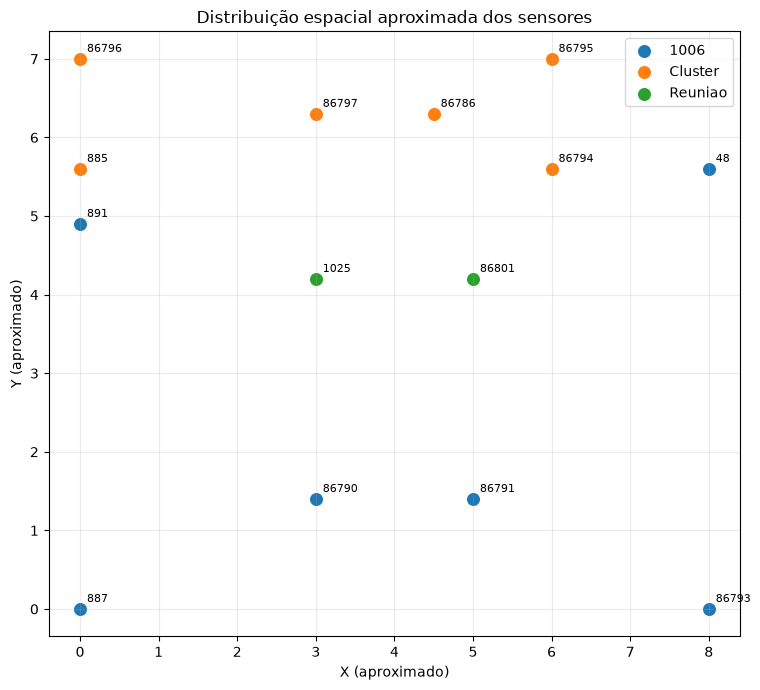

In [3]:
fig, ax = plt.subplots(figsize=(10, 7))
for regiao, grupo in metadata.groupby("regiao"):
    ax.scatter(grupo.x_aprox, grupo.y_aprox, s=70, label=regiao)
    for r in grupo.itertuples():
        ax.annotate(str(r.id_device), (r.x_aprox, r.y_aprox), xytext=(5, 5),
                    textcoords="offset points", fontsize=8)
ax.set(xlabel="X (aproximado)", ylabel="Y (aproximado)",
       title="Distribuição espacial aproximada dos sensores")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "mapa_sensores_aproximado.png", dpi=160)
plt.show()

3. Autenticação e conferência do cadastro
O servidor utiliza HTTP; portanto, a senha pode trafegar sem criptografia de transporte. Use somente em rede e ambiente autorizados. Prefira HTTPS caso esteja disponível. Não imprima o token ou a senha.

In [ ]:
import os
from getpass import getpass

session = requests.Session()
usuario = os.environ.get("SMARTLAB_USERNAME") or input("Usuário Smartlab: ")
senha = os.environ.get("SMARTLAB_PASSWORD") or getpass("Senha Smartlab: ")
login = session.post(
    f"{BASE_URL}/auth/login",
    json={"username": usuario, "password": senha}, timeout=30
)
del senha
login.raise_for_status()
token = login.json().get("token")
if not token:
    raise RuntimeError("Login sem campo 'token'. Verifique o formato da resposta.")
session.headers.update({"Authorization": f"Bearer {token}"})
del token
print("Autenticado; token armazenado apenas na sessão em memória.")


In [111]:
r = session.get(f"{BASE_URL}/device", timeout=30)
r.raise_for_status()
cadastro = pd.DataFrame(r.json())
if not {"id", "name", "id_enviroment"}.issubset(cadastro.columns):
    raise ValueError(f"Colunas inesperadas no cadastro: {list(cadastro.columns)}")
conferencia = metadata.merge(
    cadastro[["id", "name", "id_enviroment"]].rename(columns={
        "id": "id_device", "name": "nome_api", "id_enviroment": "ambiente_api"}),
    on="id_device", how="left", validate="one_to_one"
)
conferencia["ambiente_confere"] = (
    pd.to_numeric(conferencia.ambiente_api, errors="coerce") == conferencia.id_environment
)
display(conferencia[["id_device", "nome", "nome_api", "id_environment", "ambiente_api", "ambiente_confere"]])
if not conferencia.ambiente_confere.all():
    print("ATENÇÃO: há IDs/ambientes não confirmados. Corrija o inventário antes da coleta.")


,id_device,nome,nome_api,id_environment,ambiente_api,ambiente_confere
0,887,1006-esp32-temphum-09,1006-TEMPHUM-09,1,1.0,True
1,86790,1006-esp32-temphum-02,1006-TEMPHUM-02,1,1.0,True
2,86791,1006-esp32-temphum-03,1006-TEMPHUM-03,1,1.0,True
3,86793,1006-esp32-temphum-08,1006-TEMPHUM-08,1,1.0,True
4,891,1006-esp32-temphum-06,1006-TEMPHUM-06,1,1.0,True
5,1025,1008Reuniao-esp32-temphum-03,1008REUNIAO-TEMPHUM-03,2,2.0,True
6,86801,1008Reuniao-esp32-temphum-04,1008REUNIAO-TEMPHUM-04,2,2.0,True
7,48,1006-esp32-temphum-07,1006-TEMPHUM-07,1,1.0,True
8,86796,1006Cluster-esp32-temphum-03,1006CLUSTER-TEMPHUM-03,3,3.0,True
9,885,1006Cluster-esp32-temphum-04,1006CLUSTER-TEMPHUM-04,3,3.0,True


Conferir o tipo de dispositivo
O valor idDeviceType=1 foi usado com sucesso em uma consulta de temperatura, mas é recomendável conferir o catálogo de tipos da API.

In [112]:
r_tipos = session.get(f"{BASE_URL}/guest/deviceTypes", timeout=30)
print("Status /guest/deviceTypes:", r_tipos.status_code)
if r_tipos.ok:
    tipos = r_tipos.json()
    display(pd.DataFrame(tipos) if isinstance(tipos, list) else tipos)
else:
    print("Não foi possível consultar o catálogo; confirme manualmente idDeviceType=1.")


Status /guest/deviceTypes: 200


,id,name
0,10,Brightness
1,11,Energy
2,12,Presence
3,13,Umidade de Solo
4,14,Temperatura de Solo
5,15,Sensor de Fluxo
6,1,Temperature
7,2,Humidity


4. Função de coleta individual
- Faz consultas por dia para reduzir o risco de timeout.
- Converte avg_value, min_value e max_value para números; NaN textual vira valor ausente.
- Preserva o timestamp exatamente como devolvido pela API (sem assumir UTC). O Z da requisição indica UTC, mas ainda precisamos confirmar o fuso da resposta.
- Guarda também a resposta bruta por sensor para auditoria.
- Não interpola dados ausentes.

In [113]:
def consultar_sensor(id_device, id_environment, inicio, fim, time_bucket="5min"):
    payload = {
        "startDate": inicio,
        "endDate": fim,
        "idDeviceType": TIPO_TEMPERATURA,
        "idEnviroment": int(id_environment),
        "idDevice": int(id_device),
        "timeBucket": time_bucket,
    }
    resp = session.post(f"{BASE_URL}/datastream/filter", json=payload, timeout=90)
    resp.raise_for_status()
    dados = resp.json()
    if not isinstance(dados, list):
        raise ValueError(f"Resposta inesperada do sensor {id_device}: {type(dados).__name__}")
    df = pd.DataFrame(dados)
    if df.empty:
        return pd.DataFrame(columns=["time_interval", "avg_value", "min_value", "max_value", "id_device"])
    obrigatorias = {"time_interval", "avg_value"}
    if not obrigatorias.issubset(df.columns):
        raise ValueError(f"Campos inesperados para {id_device}: {list(df.columns)}")
    for campo in ("avg_value", "min_value", "max_value"):
        if campo in df:
            df[campo] = pd.to_numeric(df[campo], errors="coerce")
    df["id_device"] = int(id_device)
    return df


def janelas_diarias(inicio, fim):
    # As datas de entrada são UTC; usamos limites diários de consulta.
    a = pd.Timestamp(inicio)
    b = pd.Timestamp(fim)
    if a.tzinfo is None or b.tzinfo is None or a >= b:
        raise ValueError("Use datas ISO com fuso e início anterior ao fim")
    while a < b:
        proximo = min(a + pd.Timedelta(days=1), b)
        yield a.isoformat().replace("+00:00", "Z"), proximo.isoformat().replace("+00:00", "Z")
        a = proximo


def coletar_periodo(sensor, inicio, fim, pausa=0.1):
    partes = []

    for a, b in janelas_diarias(inicio, fim):
        try:
            df = consultar_sensor(
                sensor.id_device,
                sensor.id_environment,
                a,
                b,
                TIME_BUCKET
            )

            partes.append(df)

        except (requests.RequestException, ValueError) as exc:
            raise RuntimeError(
                f"Falha no sensor {sensor.id_device}, "
                f"janela {a} a {b}: {exc}"
            ) from exc

        time.sleep(pausa)

    if not partes:
        return pd.DataFrame()

    resultado = pd.concat(partes, ignore_index=True)

    resultado = resultado.drop_duplicates()

    return resultado

5. Teste de sanidade (um sensor, um dia)
Antes de coletar todos os dispositivos, valide a resposta do sensor 86794, que já retornou dados horários anteriormente. Para um dia completo, a resolução de cinco minutos permite até 288 intervalos, mas a API pode retornar menos, mais ou timestamps duplicados.

In [114]:
teste = consultar_sensor(86794, 3, "2026-06-28T00:00:00Z", "2026-06-29T00:00:00Z")
print("Linhas:", len(teste))
display(teste.head())
print("Valores inválidos em avg_value:", teste.avg_value.isna().sum())
print("Timestamps repetidos:", teste.time_interval.duplicated().sum())


Linhas: 2115


,time_interval,avg_value,min_value,max_value,id_device
0,2026-06-28T00:00:00,18.8,18.8,18.8,86794
1,2026-06-28T00:00:30,18.8,18.8,18.8,86794
2,2026-06-28T00:01:00,18.8,18.8,18.8,86794
3,2026-06-28T00:02:30,18.8,18.8,18.8,86794
4,2026-06-28T00:03:00,18.8,18.8,18.8,86794


Valores inválidos em avg_value: 0
Timestamps repetidos: 0


6. Coleta dos 14 sensores
Primeira execução: mantenha EXECUTAR_PERIODO_COMPLETO = False e valide um dia. Só depois ative a janela completa no início do notebook e execute novamente. A coleta completa pode fazer centenas de requisições; respeite as condições de uso do servidor.

O arquivo CSV de cada sensor contém as respostas da API e pode ser reutilizado sem novas requisições.

In [4]:
coletados = {}
falhas = {}

for sensor in metadata.itertuples(index=False):

    arquivo = RAW_DIR / (
        f"sensor_{sensor.id_device}_{INICIO[:10]}_{FIM[:10]}.csv"
    )

    try:
        if arquivo.exists():
            print(f"{sensor.id_device:>6} | Carregando CSV existente")

            df = pd.read_csv(arquivo)

        else:
            df = coletar_periodo(sensor, INICIO, FIM)

            df.to_csv(arquivo, index=False)

        coletados[sensor.id_device] = df

        print(
            f"{sensor.id_device:>6} | "
            f"{sensor.regiao:<7} | "
            f"{len(df):>6} linhas"
        )

    except Exception as exc:
        falhas[sensor.id_device] = str(exc)

        print(
            f"{sensor.id_device:>6} | "
            f"FALHA: {exc}"
        )

print(
    f"\nConcluído: {len(coletados)} sensores; "
    f"falhas: {len(falhas)}"
)

if falhas:
    display(
        pd.DataFrame([
            {"id_device": k, "erro": v}
            for k, v in falhas.items()
        ])
    )

   887 | Carregando CSV existente
   887 | 1006    |  96077 linhas
 86790 | Carregando CSV existente
 86790 | 1006    |  97309 linhas
 86791 | Carregando CSV existente
 86791 | 1006    |  96044 linhas
 86793 | Carregando CSV existente
 86793 | 1006    |  97389 linhas
   891 | Carregando CSV existente
   891 | 1006    |  97318 linhas
  1025 | Carregando CSV existente


  1025 | Reuniao |  96988 linhas
 86801 | Carregando CSV existente
 86801 | Reuniao |  96165 linhas
    48 | Carregando CSV existente
    48 | 1006    |  92083 linhas
 86796 | Carregando CSV existente
 86796 | Cluster |  97983 linhas
   885 | Carregando CSV existente
   885 | Cluster |  97280 linhas
 86797 | Carregando CSV existente
 86797 | Cluster |  96683 linhas
 86786 | Carregando CSV existente


 86786 | Cluster |  96773 linhas
 86795 | Carregando CSV existente
 86795 | Cluster |  96308 linhas
 86794 | Carregando CSV existente
 86794 | Cluster |  97136 linhas

Concluído: 14 sensores; falhas: 0


## Construção das matrizes e disponibilidade exploratória

Os CSVs da API contêm mais de uma linha por intervalo de cinco minutos. A cobertura abaixo
conta janelas ocupadas depois da agregação, sobre a grade completa solicitada, e não linhas
retornadas. A convenção temporal das respostas ainda não está equiparada ao UTC: os limites
são comparados apenas pelos horários textuais, como diagnóstico exploratório. Essas proporções
não devem ser comparadas ao QuestDB como cobertura temporal já validada.

A média simples de `avg_value` dentro de cinco minutos é exploratória, pois a API não fornece
a quantidade de medições que originou cada média. Duplicatas conflitantes interrompem o
processamento, em vez de serem resolvidas pela escolha arbitrária de uma linha.


In [5]:
series = []
resumos = []
# Grade nominal sem atribuir fuso aos timestamps sem timezone da API.
grade_nominal = pd.date_range(pd.Timestamp(INICIO).tz_localize(None),
                             pd.Timestamp(FIM).tz_localize(None),
                             freq="5min", inclusive="left", name="timestamp")
expected = len(grade_nominal)
for sensor in metadata.itertuples(index=False):
    df = coletados.get(sensor.id_device)
    if df is None or df.empty:
        resumos.append({"id_device": sensor.id_device, "regiao": sensor.regiao,
                        "status": "falha" if df is None else "sem registros",
                        "registros": 0, "validos": 0, "cobertura_nominal_pct": 0.0})
        continue
    t = df.copy()
    t["timestamp"] = pd.to_datetime(t["time_interval"], errors="coerce")
    if t.timestamp.dt.tz is not None:
        raise ValueError("A API passou a retornar fuso: confira a convenção antes de prosseguir.")
    t["avg_value"] = pd.to_numeric(t["avg_value"], errors="coerce")
    invalid_ts = int(t.timestamp.isna().sum())
    duplicates = int(t.timestamp.duplicated().sum())
    t = t.dropna(subset=["timestamp"]).sort_values("timestamp")
    conflitos = t.groupby("timestamp").avg_value.nunique(dropna=False).gt(1)
    if conflitos.any():
        raise ValueError(f"Valores conflitantes no mesmo timestamp: sensor {sensor.id_device}")
    t = t.drop_duplicates(subset=["timestamp"])
    s = t.set_index("timestamp")["avg_value"].rename(str(sensor.id_device))
    series.append(s)
    agregado = s.resample("5min").mean().reindex(grade_nominal)
    validos = int(agregado.notna().sum())
    resumos.append({"id_device": sensor.id_device, "regiao": sensor.regiao, "status": "ok",
                    "registros": len(df), "validos": validos,
                    "timestamps_invalidos": invalid_ts, "timestamps_duplicados": duplicates,
                    "primeiro_timestamp": s.index.min(), "ultimo_timestamp": s.index.max(),
                    "cobertura_nominal_pct": 100 * validos / expected,
                    "media_c": agregado.mean(), "min_c": agregado.min(),
                    "max_c": agregado.max(), "desvio_c": agregado.std()})
matriz = pd.concat(series, axis=1, sort=True).sort_index() if series else pd.DataFrame()
resumo = pd.DataFrame(resumos)
assert resumo.cobertura_nominal_pct.between(0, 100).all()
display(resumo)
print("Janelas na grade nominal:", expected)
print("Matriz de timestamps retornados:", matriz.shape)
resumo.to_csv(META_DIR / "cobertura_sensores.csv", index=False)
matriz.to_csv(RAW_DIR / "matriz_exploratoria.csv", index_label="timestamp")


,id_device,regiao,status,registros,validos,timestamps_invalidos,timestamps_duplicados,primeiro_timestamp,ultimo_timestamp,cobertura_nominal_pct,media_c,min_c,max_c,desvio_c
0,887,1006,ok,96077,12902,0,0,2026-06-10 00:00:30,2026-07-25 06:58:00,97.388285,22.616715,19.605556,25.800000,1.154439
1,86790,1006,ok,97309,12902,0,0,2026-06-10 00:01:00,2026-07-25 06:58:30,97.388285,24.018540,20.185714,27.325000,1.156236
2,86791,1006,ok,96044,12902,0,0,2026-06-10 00:00:00,2026-07-25 06:58:30,97.388285,23.275342,19.185714,26.681250,1.169473
3,86793,1006,ok,97389,12902,0,0,2026-06-10 00:00:00,2026-07-25 06:58:30,97.388285,22.496089,19.000000,26.822222,1.278245
4,891,1006,ok,97318,12901,0,0,2026-06-10 00:00:00,2026-07-25 06:58:30,97.380737,19.848436,18.000000,22.600000,0.805320
5,1025,Reuniao,ok,96988,12902,0,0,2026-06-10 00:00:00,2026-07-25 06:58:30,97.388285,22.901132,19.161111,27.750000,1.317321
6,86801,Reuniao,ok,96165,12902,0,0,2026-06-10 00:00:00,2026-07-25 06:58:00,97.388285,22.506609,18.875000,25.992857,1.160814
7,48,1006,ok,92083,12877,0,0,2026-06-10 00:00:00,2026-07-25 06:58:00,97.199577,22.112338,19.305000,24.800000,0.993654
8,86796,Cluster,ok,97983,12902,0,0,2026-06-10 00:00:00,2026-07-25 06:58:30,97.388285,17.149746,15.600000,18.843750,0.443101
9,885,Cluster,ok,97280,12902,0,0,2026-06-10 00:00:00,2026-07-25 06:58:30,97.388285,13.009385,10.575000,14.800000,0.572218


Janelas na grade nominal: 13248
Matriz de timestamps retornados: (128984, 14)


8. Simultaneidade e estatísticas exploratórias
O percentual de linhas completas considera os timestamps presentes na união das séries. A análise de cobertura por sensor está na tabela anterior. Valores extremos não serão excluídos automaticamente.

In [6]:
if not matriz.empty:
    print("Linhas na união temporal:", len(matriz))
    print("Linhas com todos os sensores válidos:", int(matriz.notna().all(axis=1).sum()))
    print("Proporção de linhas completas (%):", round(100 * matriz.notna().all(axis=1).mean(), 2))
    display(matriz.describe().T.round(2))
    display(matriz.corr(min_periods=20).round(2))
else:
    print("Sem séries para analisar.")


Linhas na união temporal: 128984
Linhas com todos os sensores válidos: 2186
Proporção de linhas completas (%): 1.69


,count,mean,std,min,25%,50%,75%,max
887,96077.0,22.61,1.15,19.6,21.9,22.6,23.30,25.8
86790,97309.0,24.03,1.16,20.1,23.3,24.0,24.70,27.4
86791,96044.0,23.27,1.17,19.1,22.6,23.3,24.00,26.8
86793,97389.0,22.51,1.28,18.9,21.7,22.5,23.30,26.9
891,97318.0,19.85,0.81,17.9,19.3,19.8,20.30,22.7
1025,96988.0,22.90,1.32,19.0,22.1,22.8,23.70,27.8
86801,96165.0,22.51,1.17,18.7,21.8,22.5,23.25,26.0
48,92082.0,22.14,1.00,19.2,21.5,22.2,22.70,24.9
86796,97983.0,17.15,0.45,15.5,16.9,17.2,17.40,18.9
885,97280.0,13.01,0.57,10.5,12.8,13.1,13.40,14.8


,887,86790,86791,86793,891,1025,86801,48,86796,885,86797,86786,86795,86794
887,1.00,0.91,0.81,0.94,0.86,0.73,0.77,0.92,0.48,0.25,0.48,0.64,0.68,0.66
86790,0.91,1.00,0.91,0.90,0.88,0.81,0.82,0.95,0.43,0.25,0.44,0.59,0.69,0.63
86791,0.81,0.91,1.00,0.81,0.85,0.83,0.85,0.91,0.41,0.26,0.42,0.51,0.64,0.58
86793,0.94,0.90,0.81,1.00,0.77,0.65,0.69,0.87,0.39,0.15,0.36,0.60,0.70,0.60
891,0.86,0.88,0.85,0.77,1.00,0.91,0.90,0.93,0.67,0.54,0.68,0.70,0.61,0.71
1025,0.73,0.81,0.83,0.65,0.91,1.00,0.93,0.84,0.55,0.44,0.60,0.57,0.53,0.59
86801,0.77,0.82,0.85,0.69,0.90,0.93,1.00,0.86,0.56,0.43,0.58,0.56,0.54,0.63
48,0.92,0.95,0.91,0.87,0.93,0.84,0.86,1.00,0.47,0.30,0.51,0.61,0.67,0.67
86796,0.48,0.43,0.41,0.39,0.67,0.55,0.56,0.47,1.00,0.88,0.82,0.73,0.34,0.68
885,0.25,0.25,0.26,0.15,0.54,0.44,0.43,0.30,0.88,1.00,0.82,0.60,0.14,0.53


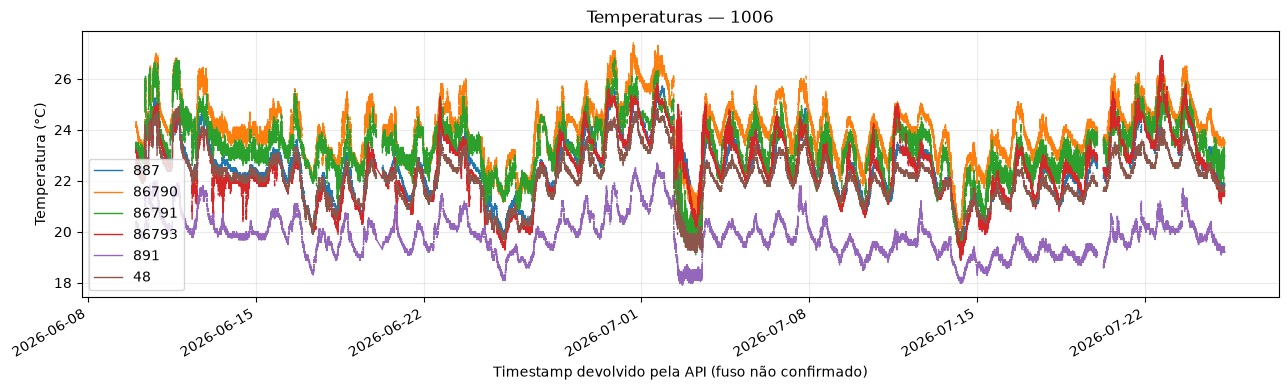

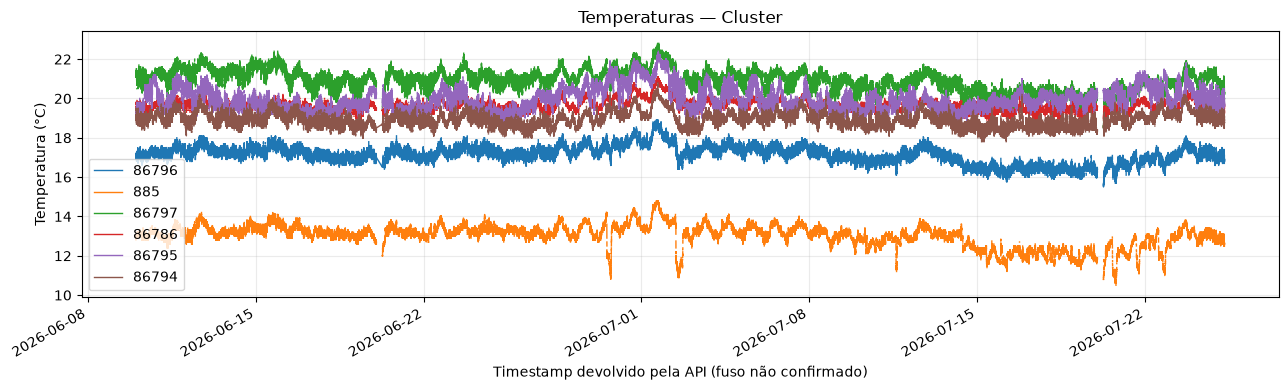

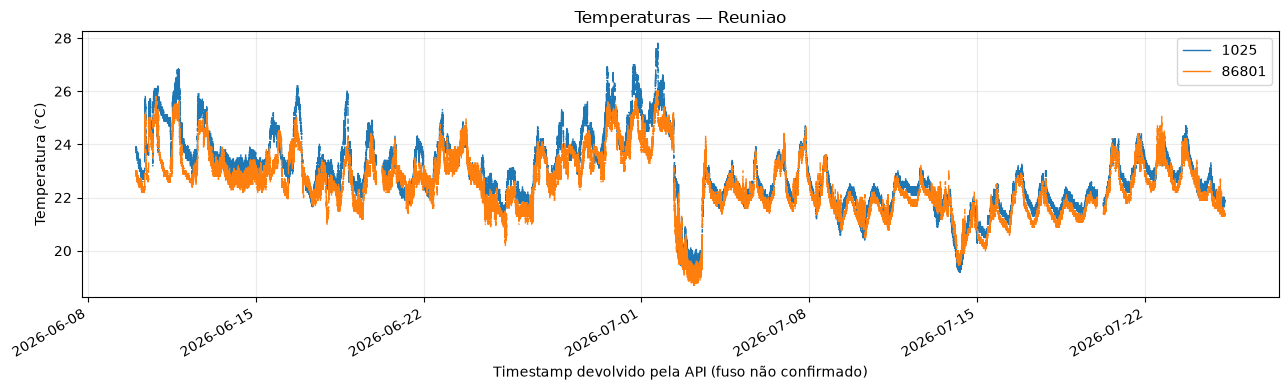

In [7]:
if not matriz.empty:
    for regiao, grupo in metadata.groupby("regiao"):
        cols = [str(i) for i in grupo.id_device if str(i) in matriz.columns]
        if not cols:
            continue
        ax = matriz[cols].plot(figsize=(13, 4), linewidth=1, title=f"Temperaturas — {regiao}")
        ax.set(xlabel="Timestamp devolvido pela API (fuso não confirmado)", ylabel="Temperatura (°C)")
        ax.grid(alpha=0.25)
        plt.tight_layout()
        plt.savefig(FIG_DIR / f"temperaturas_{regiao.lower()}.png", dpi=160)
        plt.show()


9. Verificações antes do notebook 02
Preencha/registre estas decisões após executar o notebook:
1. Identificadores e ambientes: todos os 14 sensores foram confirmados no cadastro? Se não, corrigir.
2. Tipo de dado: idDeviceType=1 corresponde efetivamente à temperatura?
3. Timestamp: qual é o fuso da resposta da API? Comparar um sensor e instante com o QuestDB antes de mesclar fontes.
4. Intervalos: os horários devolvidos seguem a grade de cinco minutos? Existem duplicatas ou lacunas?
5. Cobertura: quais sensores têm medições simultâneas suficientes para os experimentos?
6. Fonte: manter QuestDB como base já validada até confirmar equivalência e qualidade da API.
Saídas: data/metadata/sensores.csv, data/metadata/cobertura_sensores.csv, arquivos por sensor em data/raw/smartlab/, matriz exploratória e gráficos em results/figuras/.

Próximo notebook: 02_preprocessamento.ipynb, para padronizar timestamps, definir períodos e produzir matrizes experimentais sem vazamento de informação.

In [8]:
# Agregação exploratória para intervalos de 5 minutos

matriz_5min = (
    matriz
    .resample("5min")
    .mean()
    .reindex(grade_nominal)
)

print("Matriz original:", matriz.shape)
print("Matriz de 5 minutos:", matriz_5min.shape)

for regiao, grupo in metadata.groupby("regiao"):
    colunas = [
        str(i)
        for i in grupo.id_device
        if str(i) in matriz_5min.columns
    ]

    if not colunas:
        continue

    dados = matriz_5min[colunas]

    print(f"\nRegião: {regiao}")
    print("Sensores:", len(colunas))
    print("Intervalos:", len(dados))
    print("Intervalos completos:", dados.dropna().shape[0])
    print(
        "Cobertura simultânea nominal (fuso pendente):",
        f"{100 * dados.notna().all(axis=1).mean():.2f}%"
    )

Matriz original: (128984, 14)
Matriz de 5 minutos: (13248, 14)

Região: 1006
Sensores: 6
Intervalos: 13248
Intervalos completos: 12876
Cobertura simultânea nominal (fuso pendente): 97.19%

Região: Cluster
Sensores: 6
Intervalos: 13248
Intervalos completos: 12902
Cobertura simultânea nominal (fuso pendente): 97.39%

Região: Reuniao
Sensores: 2
Intervalos: 13248
Intervalos completos: 12902
Cobertura simultânea nominal (fuso pendente): 97.39%
